<div dir="rtl">

# کارگاه جلسه ۲۲ — درخت تصمیم

هر بخش مستقل است. نوشتن این کدها در امتحان پرسیده نمی‌شود.

## تمرین عملی کلاس (۲۵ دقیقه): کشور سازنده خودرو

در داده mpg، ستون `origin` کشور سازنده (usa، europe، japan) است؛ یک مسئله **سه‌کلاسه**.

1. سطرهای بدون قدرت موتور را حذف کنید. ویژگی‌ها: cylinders، displacement، horsepower، weight، acceleration، model_year و mpg. داده را با ۲۰ درصد آزمون (طبقه‌بندی‌شده، `random_state=42`) تقسیم کنید.
2. دقت اعتبارسنجی ۵ بخشی (طبقه‌بندی‌شده) مدل پایه، درخت کامل و درخت با عمق ۳ را مقایسه کنید.
3. با `GridSearchCV` روی `max_depth` (۱ تا ۱۰) و `criterion` (gini و entropy) بهترین درخت را پیدا کنید. آیا جینی و آنتروپی تفاوت معناداری دارند؟
4. درخت عمق ۳ را با `plot_tree` رسم کنید. اولین پرسش درخت چیست و چه معنایی دارد؟
5. دقت آزمون بهترین درخت را گزارش کنید و با `pd.crosstab` ببینید کدام کشورها با هم اشتباه گرفته می‌شوند.

</div>

In [1]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

{'usa': 0.626, 'japan': 0.201, 'europe': 0.173}
Baseline   CV accuracy=0.626
Full tree  CV accuracy=0.805
Depth 3    CV accuracy=0.751


criterion  entropy   gini
max_depth                
1            0.649  0.719
2            0.728  0.703
3            0.748  0.751
4            0.767  0.751
5            0.767  0.770
6            0.770  0.802
7            0.805  0.776
8            0.802  0.802
9            0.799  0.799
10           0.799  0.805
best={'criterion': 'entropy', 'max_depth': 7}  CV accuracy=0.805  test accuracy=0.861
predicted  europe  japan  usa
actual                       
europe         10      1    3
japan           1     13    2
usa             2      2   45


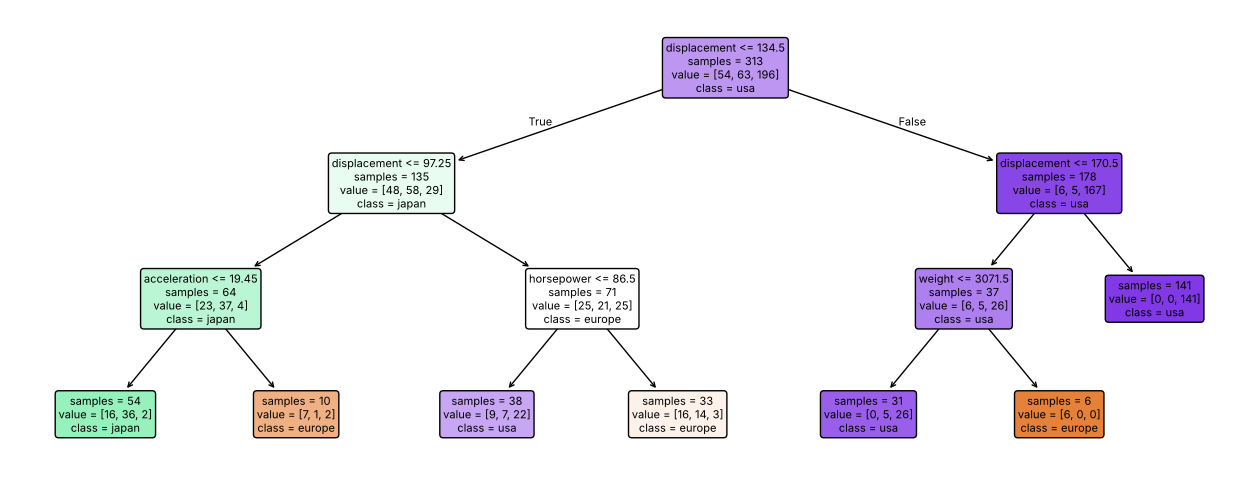

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier

mpg = sns.load_dataset("mpg").dropna(subset=["horsepower"])
features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "mpg"]
X_train, X_test, y_train, y_test = train_test_split(mpg[features], mpg["origin"], test_size=0.2,
                                                    stratify=mpg["origin"], random_state=42)
print(y_train.value_counts(normalize=True).round(3).to_dict())
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, m in {"Baseline": DummyClassifier(),
                "Full tree": DecisionTreeClassifier(random_state=42),
                "Depth 3": DecisionTreeClassifier(max_depth=3, random_state=42)}.items():
    print(f"{name:10s} CV accuracy={cross_val_score(m, X_train, y_train, cv=cv).mean():.3f}")

gs = GridSearchCV(DecisionTreeClassifier(random_state=42),
                  {"max_depth": range(1, 11), "criterion": ["gini", "entropy"]}, cv=cv).fit(X_train, y_train)
res = pd.DataFrame(gs.cv_results_["params"])
res["cv"] = gs.cv_results_["mean_test_score"].round(3)
print(res.pivot(index="max_depth", columns="criterion", values="cv"))
print(f"best={gs.best_params_}  CV accuracy={gs.best_score_:.3f}  test accuracy={gs.score(X_test, y_test):.3f}")
print(pd.crosstab(y_test, gs.predict(X_test), rownames=["actual"], colnames=["predicted"]))

small = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(small, feature_names=features, class_names=list(small.classes_), filled=True,
          impurity=False, rounded=True, fontsize=8, ax=ax)
plt.show()

<div dir="rtl">

### پاسخ‌های کلیدی

- سهم کلاس‌ها در آموزش: usa ۰.۶۲۶، japan ۰.۲۰۱ و europe ۰.۱۷۳؛ مدل پایه دقت ۰.۶۲۶ دارد.
- دقت اعتبارسنجی: درخت کامل **۰.۸۰۵** و درخت عمق ۳ حدود ۰.۷۵۱. اینجا درخت کامل بد نیست، چون کشور سازنده با مشخصات فنی رابطه پیچیده‌ای دارد.
- جست‌وجوی شبکه‌ای: بهترین ترکیب آنتروپی با عمق ۷ (اعتبارسنجی ۰.۸۰۵) است، اما جینی با عمق ۶، ۸ یا ۱۰ تقریباً همان دقت را دارد (۰.۸۰۲ تا ۰.۸۰۵). تفاوت دو معیار در حد نوسان بخش‌هاست.
- اولین پرسش درخت عمق ۳: «حجم موتور حداکثر ۱۳۴.۵ اینچ مکعب است؟». موتورهای بزرگ (بیش از ۱۷۰.۵) تقریباً همه آمریکایی‌اند؛ خودروهای کوچک ژاپنی یا اروپایی‌اند و درخت آن‌ها را با شتاب و قدرت از هم جدا می‌کند.
- دقت آزمون بهترین درخت **۰.۸۶۱** است (روی ۷۹ خودرو، بیشتر از برآورد اعتبارسنجی؛ نوسان تقسیم کوچک). بیشترین اشتباه: سه خودروی اروپایی که آمریکایی پیش‌بینی شده‌اند.

</div>